# 03. Pipeline Core — Arquitetura CNN–LSTM
### Previsão de Séries Temporais Financeiras (*Jane Street Real-Time Market Data*)

Este notebook implementa o treinamento e avaliação comparativa da arquitetura híbrida **CNN–LSTM** (`Conv1D` → `MaxPooling1D` → `LSTM`) sobre o **mesmo pipeline Core** do `03_core_lstm.ipynb`:

1. **Suporte Nativo ao Google Colab:** Detecção automática de ambiente, montagem do Google Drive e cópia de `train.parquet`, `val.parquet` e `test.parquet` para `/content/processed`.
2. **Aceleração com Precisão Mista (`mixed_float16`):** Redução de VRAM e aceleração na GPU Tesla T4, mantendo a camada densa de saída em `float32`.
3. **Protocolo Temporal Estrito (70% / 15% / 15%):** Mesmos splits cronológicos, mesmas Top 40 *features*, mesmo `SEQ_LEN = 128`, `stride = 16`, `batch_size` e semente (`SEED = 42`) do Core LSTM.
4. **Extração Local + Recorrência (`Conv1D` Causal → `MaxPooling1D` → `LSTM`):** A convolução 1D causal extrai padrões locais de curto prazo e o *pooling* reduz ruído de alta frequência antes da camada recorrente `LSTM`.
5. **Treinamento Alinhado à Métrica Oficial:** Loss `MSE` nativa com `sample_weight=weight`, `Adam(lr=1e-3)`, `ReduceLROnPlateau`, `EarlyStopping`, `CSVLogger` e avaliação global via **Zero-Mean Weighted $R^2$**.

---
## Ficha Técnica do Experimento

### 1. Resumo do Protocolo Experimental

| Dimensão | Configuração Adotada | Justificativa Técnica |
| :--- | :--- | :--- |
| **Dataset & Recorte** | Jane Street (`date_id >= 700`, 39 ativos) | Estabilização estrutural em 968 `time_id`s/dia (EDA Seção 2) |
| **Divisão Temporal** | 70% Treino (`700–1398`) / 15% Val (`1399–1547`) / 15% Teste (`1548–1698`) | Idêntica ao Core LSTM para comparação justa (zero *data leakage*) |
| **Entrada (`X`)** | Top 40 *features* (`StandardScaler` no treino + `NaN = 0.0`) | Poda de colinearidade (79 → 40) sem vazamento |
| **Sequenciamento 3D** | Janelas `(T = 128, F = 40)`, `stride = 16`, `batch_size = 4096` | Respeita fronteiras `(symbol_id, date_id)` e filtra `weight > 0` |
| **Hipótese Testada** | `Conv1D (causal)` → `MaxPooling1D` → `LSTM(64)` | Extrair padrões locais e suavizar ruído intradiário antes da recorrência |
| **Otimização** | `Adam(lr=1e-3)` + `ReduceLROnPlateau(patience=2, factor=0.5)` + `EarlyStopping(patience=5)` | Mesmo protocolo de regularização do Core LSTM |

### 2. Arquitetura Explicada — `Core_CNN_LSTM`

```text
Input (128 passos intradiários × 40 features)
   │
   ▼
Conv1D(filters=64, kernel_size=3, padding='causal', activation='relu')
   │                                  ← Extrai padrões locais de 3 passos (causal: sem look-ahead bias)
   │                                  ← padding="causal" → saída(t) usa [t-2, t-1,  t ]   só passado e presente
   ▼
MaxPooling1D(pool_size=2)          ← Reduz sequência (128 → 64) e atenua ruído de alta frequência
   │
   ▼
LSTM(64, return_sequences=False)   ← Captura dependências temporais sobre as representações locais
   │
   ▼
Dense(64, activation='relu')       ← Projeção não linear
   │
   ▼
Dropout(0.2)                       ← Regularização contra overfitting
   │
   ▼
Dense(1, linear, dtype='float32')  ← Regressão contínua de responder_6 (estabilidade sob mixed_float16)
```

### 3. Separação Explícita: Função de Custo (*Loss*) vs. Métrica de Avaliação

- **Função de Custo no Treinamento (Nativa — sem custo customizado):** `loss="mse"` nativo do Keras com `sample_weight=weight` (equivalente a maximizar o *Weighted $R^2$*).
- **Métrica de Avaliação Global (`WeightedR2Callback`):** **não é uma *loss*** e não altera os gradientes; calcula globalmente o **Zero-Mean Weighted $R^2$**, `RMSE` e `MAE` em `float64` ao fim de cada época:
  $$R^2_w = 1 - \frac{\sum_{i=1}^{N} w_i (y_i - \hat{y}_i)^2}{\sum_{i=1}^{N} w_i y_i^2}$$

---
## 1. Importação de Bibliotecas, Ambiente e Hiperparâmetros do Core

Configuramos as bibliotecas, a detecção automática do Google Colab, a política de precisão mista (`mixed_float16`), a estratégia de GPU e os hiperparâmetros padronizados do experimento.

In [1]:
# 1.1 Importação de bibliotecas e estilo visual
import os
import sys
import gc
import json
import time
import shutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from numpy.lib.stride_tricks import sliding_window_view
from tensorflow.keras import layers, models, callbacks, optimizers, mixed_precision

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 120

In [2]:
# 1.2 Suporte automático para execução no Google Colab
IN_COLAB = 'google.colab' in sys.modules
if IN_COLAB:
    print("[*] Google Colab detectado! Montando Google Drive...")
    from google.colab import drive
    drive.mount('/content/drive')
    PROJECT_ROOT = '/content/drive/MyDrive/ProjetosRedesNeurais/Unidade3'
    if os.path.exists(PROJECT_ROOT):
        os.chdir(PROJECT_ROOT)
        print(f"[*] Diretório de trabalho: {os.getcwd()}")
    else:
        raise FileNotFoundError(f"Diretório não encontrado no Drive: {PROJECT_ROOT}")
else:
    print("[*] Ambiente Local detectado!")

Mounted at /content/drive
[*] Diretório de trabalho: /content/drive/MyDrive/ProjetosRedesNeurais/Unidade3


In [3]:
# 1.3 Precisão Mista (mixed_float16) e detecção de aceleradores (GPU / CPU)
gpus = tf.config.list_physical_devices("GPU")
for gpu in gpus:
    try:
        tf.config.experimental.set_memory_growth(gpu, True)
    except Exception:
        pass

if gpus:
    mixed_precision.set_global_policy("mixed_float16")
    print(f"[*] GPU detectada ({len(gpus)}). Precisão mista ativada: {mixed_precision.global_policy().name}")
else:
    print("[!] Nenhuma GPU detectada — mantendo float32 em CPU.")

strategy = tf.distribute.get_strategy()

print(f"[*] TensorFlow: {tf.__version__} | Réplicas em sincronia: {strategy.num_replicas_in_sync}")

[*] GPU detectada (1). Precisão mista ativada: mixed_float16
[*] TensorFlow: 2.21.0 | Réplicas em sincronia: 1


In [4]:
# 1.4 Diretórios do projeto, prefixo e hiperparâmetros do Core
DATA_DIR = "data/processed"
LOCAL_DATA_DIR = "/content/processed" if IN_COLAB else DATA_DIR
MODELS_DIR = "models"
GRAPHS_DIR = "graphs"
PREFIXO = "core_cnn_lstm"

os.makedirs(MODELS_DIR, exist_ok=True)
os.makedirs(GRAPHS_DIR, exist_ok=True)

SEED = 42
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

TARGET_COL = "responder_6"
SEQ_LEN = 128            # Janela intradiária T (Bloco C testará 64, 128, 256 e 968)
STRIDE_TRAIN = 16        # Passo entre janelas no treino (sobreposição de 87,5% — acelera ~16x sem perder cobertura)
STRIDE_EVAL = 16         # Passo na validação/teste (reduza para 1 na avaliação final se desejar cobertura densa)
PER_REPLICA_BATCH = 4096  # Seguro para GPU T4 (15 GB VRAM) com SEQ_LEN=128
BATCH_SIZE = PER_REPLICA_BATCH * strategy.num_replicas_in_sync
AUTOTUNE = tf.data.AUTOTUNE
EPOCHS = 30
LR = 1e-3

with open(os.path.join(DATA_DIR, "selected_features.json")) as f:
    FEATURE_COLS = json.load(f)

N_FEATURES = len(FEATURE_COLS)
print(f"[*] Features: {N_FEATURES} | Seq Len (T): {SEQ_LEN} | Stride: {STRIDE_TRAIN} | Batch: {BATCH_SIZE} | Épocas teto: {EPOCHS}")

[*] Features: 40 | Seq Len (T): 128 | Stride: 16 | Batch: 4096 | Épocas teto: 30


---
## 2. Cópia Local dos Dados Processados e Conferência dos Splits (70/15/15)

Copiamos `train.parquet`, `val.parquet` e `test.parquet` para o disco local `/content/processed` no Colab para eliminar o gargalo de I/O do Google Drive e conferimos as dimensões de cada partição.

In [5]:
# 2.1 Cópia para SSD local no Colab e carregamento de Treino e Validação
SPLIT_FILES = ["train.parquet", "val.parquet", "test.parquet"]

if IN_COLAB:
    os.makedirs(LOCAL_DATA_DIR, exist_ok=True)
    for fname in SPLIT_FILES:
        src = os.path.join(DATA_DIR, fname)
        dst = os.path.join(LOCAL_DATA_DIR, fname)
        if os.path.exists(src) and not os.path.exists(dst):
            print(f"[*] Copiando {fname} para {LOCAL_DATA_DIR}...")
            shutil.copy2(src, dst)
    print(f"[*] Arquivos disponíveis em {LOCAL_DATA_DIR}: {sorted(os.listdir(LOCAL_DATA_DIR))}")

COLS_LOAD = ["date_id", "time_id", "symbol_id", "weight", TARGET_COL] + FEATURE_COLS

tr_df = pd.read_parquet(os.path.join(LOCAL_DATA_DIR, "train.parquet"), columns=COLS_LOAD)
va_df = pd.read_parquet(os.path.join(LOCAL_DATA_DIR, "val.parquet"), columns=COLS_LOAD)

resumo_dados = pd.DataFrame([
    {"Conjunto": "Treino (70%)", "Linhas": f"{len(tr_df):,}", "date_id": f"{tr_df['date_id'].min()} – {tr_df['date_id'].max()}", "Ativos": tr_df["symbol_id"].nunique()},
    {"Conjunto": "Validação (15%)", "Linhas": f"{len(va_df):,}", "date_id": f"{va_df['date_id'].min()} – {va_df['date_id'].max()}", "Ativos": va_df["symbol_id"].nunique()},
])

display(resumo_dados)

[*] Copiando train.parquet para /content/processed...
[*] Copiando val.parquet para /content/processed...
[*] Copiando test.parquet para /content/processed...
[*] Arquivos disponíveis em /content/processed: ['test.parquet', 'train.parquet', 'val.parquet']


,Conjunto,Linhas,date_id,Ativos
0,Treino (70%),"23,736,328",700 – 1398,39
1,Validação (15%),"5,418,864",1399 – 1547,39


---
## 3. Pipeline `tf.data.Dataset` Vetorizado (Janelas Intradiárias 3D)

Como os conjuntos já estão ordenados por `["symbol_id", "date_id", "time_id"]`:
- Identificamos as fronteiras contíguas de cada `(symbol_id, date_id)` com operações vetorizadas do NumPy (sem cruzar dias ou ativos);
- Fatiamento das janelas `(T, F)` com `sliding_window_view` em C puro e entrega em **lotes prontos** (`batch_size`) para manter a GPU alimentada sem gargalo de CPU;
- Filtragem explícita de `weight > 0` em cada alvo de janela (`t = i + T - 1`).

In [6]:
# 3.1 Construtor de tf.data.Dataset vetorizado por lotes respeitando fronteiras (symbol_id, date_id)
def make_sequence_dataset(df, feature_cols, seq_len=SEQ_LEN, stride=STRIDE_TRAIN, batch_size=BATCH_SIZE, training=False):
    """Constrói um `tf.data.Dataset` em lotes de janelas 3D `(T,
        F)` sem cruzar dias ou ativos.

        Converte a tabela 2D ordenada por `(symbol_id, date_id,
        time_id)` em sequências
        intradiárias deslizantes usando `sliding_window_view`,
        filtrando amostras com
        `weight > 0` e entregando lotes `(X, y, sample_weight)`
        prontos para `model.fit()`.

        Args:
            df (pd.DataFrame): DataFrame ordenado por `["symbol_id",
            "date_id", "time_id"]`
                contendo as colunas de features, `TARGET_COL` e
                `"weight"`.
            feature_cols (list[str]): Lista ordenada das features de
            entrada (`F`).
            seq_len (int): Comprimento temporal da janela intradiária
            (`T`).
            stride (int): Passo entre janelas consecutivas dentro do
            mesmo pregão.
            batch_size (int): Quantidade de janelas por lote entregue
            à GPU.
            training (bool): Se `True`, embaralha a ordem dos blocos e
            das janelas no buffer
                a cada época (reprodutível via `SEED`).

        Returns:
            tf.data.Dataset: Dataset com `.prefetch(AUTOTUNE)` que
            produz tuplas
            `(X_batch, y_batch, w_batch)` com shapes:
                - `X_batch`: `(batch, seq_len, len(feature_cols))`
                (`float32`)
                - `y_batch`: `(batch,)` — valor de `TARGET_COL` no
                último passo da janela
                - `w_batch`: `(batch,)` — `weight` correspondente
                (usado como `sample_weight`)
    """
    X_all = df[feature_cols].to_numpy(dtype=np.float32, copy=False)
    y_all = df[TARGET_COL].to_numpy(dtype=np.float32, copy=False)
    w_all = df["weight"].to_numpy(dtype=np.float32, copy=False)

    # Como df está ordenado por (symbol_id, date_id, time_id), cada grupo é uma fatia contígua [s:e]
    sym = df["symbol_id"].to_numpy()
    day = df["date_id"].to_numpy()

    #  1. Encontrar onde começa e termina cada (ativo, dia
    breaks = np.flatnonzero((sym[1:] != sym[:-1]) | (day[1:] != day[:-1])) + 1
    starts = np.concatenate(([0], breaks))
    ends = np.concatenate((breaks, [len(df)]))
    blocos = [(int(s), int(e)) for s, e in zip(starts, ends) if (e - s) >= seq_len]

    n_features = len(feature_cols)

    def batch_generator():
        rng = np.random.default_rng(SEED) if training else None
        order = np.arange(len(blocos))
        if training:
            rng.shuffle(order)

        buf_x, buf_y, buf_w = [], [], []
        buf_count = 0

        for b in order:
            s, e = blocos[b]
            xb = X_all[s:e]
            yb = y_all[s:e]
            wb = w_all[s:e]

            n_win = (e - s) - seq_len + 1
            # 2. Cortar cada dia em janelas deslizantes de 128 passos
            win_starts = np.arange(0, n_win, stride)
            target_idx = win_starts + seq_len - 1
            valid = wb[target_idx] > 0.0
            if not np.any(valid):
                continue

            win_starts = win_starts[valid]
            target_idx = target_idx[valid]

            # sliding_window_view retorna (n_win, F, T) -> transpomos para (n_win, T, F)
            wins_x = sliding_window_view(xb, window_shape=seq_len, axis=0)[win_starts].transpose(0, 2, 1)
            wins_y = yb[target_idx]
            wins_w = wb[target_idx]

            # 3. Juntar no buffer até completar um batch_size (512)
            buf_x.append(wins_x)
            buf_y.append(wins_y)
            buf_w.append(wins_w)
            buf_count += len(wins_y)

            while buf_count >= batch_size:
                X_cat = np.concatenate(buf_x, axis=0)
                y_cat = np.concatenate(buf_y, axis=0)
                w_cat = np.concatenate(buf_w, axis=0)

                if training:
                    perm = rng.permutation(len(y_cat))
                    X_cat, y_cat, w_cat = X_cat[perm], y_cat[perm], w_cat[perm]

                yield X_cat[:batch_size], y_cat[:batch_size], w_cat[:batch_size]

                if len(y_cat) > batch_size:
                    buf_x = [X_cat[batch_size:]]
                    buf_y = [y_cat[batch_size:]]
                    buf_w = [w_cat[batch_size:]]
                    buf_count = len(buf_y[0])
                else:
                    buf_x, buf_y, buf_w = [], [], []
                    buf_count = 0

        if buf_count > 0:
            yield (
                np.concatenate(buf_x, axis=0),
                np.concatenate(buf_y, axis=0),
                np.concatenate(buf_w, axis=0),
            )

    sig = (
        tf.TensorSpec(shape=(None, seq_len, n_features), dtype=tf.float32),
        tf.TensorSpec(shape=(None,), dtype=tf.float32),
        tf.TensorSpec(shape=(None,), dtype=tf.float32),
    )

    # 4. Conectar ao TensorFlow (from_generator + prefetch)
    ds = tf.data.Dataset.from_generator(batch_generator, output_signature=sig)
    return ds.prefetch(AUTOTUNE)

train_ds = make_sequence_dataset(tr_df, FEATURE_COLS, seq_len=SEQ_LEN, stride=STRIDE_TRAIN, training=True)
val_ds = make_sequence_dataset(va_df, FEATURE_COLS, seq_len=SEQ_LEN, stride=STRIDE_EVAL, training=False)

# Teste rápido de sanidade das dimensões de um batch
xb_chk, yb_chk, wb_chk = next(iter(val_ds))
print(f"[*] Batch verificado -> X: {xb_chk.shape} | y: {yb_chk.shape} | w: {wb_chk.shape}")
del xb_chk, yb_chk, wb_chk

[*] Batch verificado -> X: (4096, 128, 40) | y: (4096,) | w: (4096,)


---
## 4. Arquitetura CNN–LSTM e Métrica Oficial (*Zero-Mean Weighted $R^2$*)

- **Função de Perda (Nativa, sem custo customizado):** `loss="mse"` nativo do Keras ponderado por `sample_weight=weight` (matematicamente equivalente a maximizar $R^2_w$).
- **Métrica de Avaliação (`WeightedR2Callback`):** não entra no cálculo de gradientes; avalia o **Zero-Mean Weighted $R^2$**, `RMSE` e `MAE` ponderados **globalmente** sobre toda a validação ao final de cada época (em `float64`), nunca como média simples por *batch*:
  $$R^2_w = 1 - \frac{\sum_i w_i (y_i - \hat{y}_i)^2}{\sum_i w_i y_i^2}$$
- **Arquitetura Core CNN–LSTM:** `Input(T, F)` → `Conv1D(64, k=3, causal, relu)` → `MaxPooling1D(2)` → `LSTM(64)` → `Dense(64, relu)` → `Dropout(0.2)` → `Dense(1, linear, dtype='float32')`.

In [7]:
# 4.1 Métricas globais ponderadas e Callback de avaliação ao fim de cada época
def compute_metrics(y_true, y_pred, weights):
    y_true = np.asarray(y_true, dtype=np.float64)
    y_pred = np.asarray(y_pred, dtype=np.float64)
    weights = np.asarray(weights, dtype=np.float64)

    num = np.sum(weights * (y_true - y_pred) ** 2)
    den = np.sum(weights * (y_true ** 2))
    r2_w = 1.0 - (num / (den + 1e-12))
    rmse_w = np.sqrt(num / (np.sum(weights) + 1e-12))
    mae_w = np.sum(weights * np.abs(y_true - y_pred)) / (np.sum(weights) + 1e-12)

    return r2_w, rmse_w, mae_w


class WeightedR2Callback(callbacks.Callback):
    def __init__(self, val_ds, save_path):
        super().__init__()
        self.val_ds = val_ds
        self.save_path = save_path
        self.best_r2 = -np.inf
        self.best_rmse = np.inf
        self.best_mae = np.inf
        self.history_r2 = []
        self.history_rmse = []
        self.history_mae = []

    def on_epoch_end(self, epoch, logs=None):
        logs = logs or {}
        y_t, y_p, w_t = [], [], []
        for xb, yb, wb in self.val_ds:
            preds = self.model(xb, training=False).numpy().reshape(-1)
            y_t.append(yb.numpy())
            y_p.append(preds)
            w_t.append(wb.numpy())

        r2_w, rmse_w, mae_w = compute_metrics(
            np.concatenate(y_t), np.concatenate(y_p), np.concatenate(w_t)
        )
        self.history_r2.append(r2_w)
        self.history_rmse.append(rmse_w)
        self.history_mae.append(mae_w)

        logs["val_weighted_r2"] = r2_w
        logs["val_rmse"] = rmse_w
        logs["val_mae"] = mae_w

        msg = ""
        if r2_w > self.best_r2:
            self.best_r2 = r2_w
            self.best_rmse = rmse_w
            self.best_mae = mae_w
            self.model.save(self.save_path)
            msg = " [*] Novo melhor modelo salvo!"
        print(f" — val_weighted_r2: {r2_w:.6f} | val_rmse: {rmse_w:.5f} | val_mae: {mae_w:.5f}{msg}")

In [8]:
# 4.2 Definição do modelo Core CNN-LSTM
def build_cnn_lstm_model(seq_len, n_features, lr=LR):
    inputs = layers.Input(shape=(seq_len, n_features), name="input_seq")
    # Convolução 1D causal: usa apenas passos t-2, t-1, t (zero look-ahead bias)
    x = layers.Conv1D(filters=64, kernel_size=3, padding="causal", activation="relu", name="conv1d_local")(inputs)
    x = layers.MaxPooling1D(pool_size=2, name="maxpool_local")(x)
    x = layers.LSTM(64, return_sequences=False, name="lstm_core")(x)
    x = layers.Dense(64, activation="relu", name="dense_hidden")(x)
    x = layers.Dropout(0.2, name="dropout_head")(x)
    # Camada final em float32 para estabilidade numérica sob mixed_float16
    outputs = layers.Dense(1, activation="linear", dtype="float32", name="responder_6")(x)

    model = models.Model(inputs=inputs, outputs=outputs, name="Core_CNN_LSTM")
    model.compile(
        optimizer=optimizers.Adam(learning_rate=lr),
        loss="mse",
    )
    return model

tf.keras.backend.clear_session()
with strategy.scope():
    model = build_cnn_lstm_model(SEQ_LEN, N_FEATURES, lr=LR)

model.summary()

Model: "Core_CNN_LSTM"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_seq (InputLayer)          │ (None, 128, 40)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_local (Conv1D)           │ (None, 128, 64)        │         7,744 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ maxpool_local (MaxPooling1D)    │ (None, 64, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_core (LSTM)                │ (None, 64)             │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_hidden (Dense)            │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_head (Dropout)          │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ responder_6 (Dense)             │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 44,993 (175.75 KB)

 Trainable params: 44,993 (175.75 KB)

 Non-trainable params: 0 (0.00 B)

---
## 5. Treinamento do Modelo (Treino 70% / Validação 15%)

Treinamos o modelo monitorando `val_weighted_r2` (modo `max`) com `ReduceLROnPlateau` (`patience=2`, `factor=0.5`), `EarlyStopping` (`patience=5`) e persistência do histórico em `models/core_cnn_lstm_history.csv`.

In [9]:
# 5.1 Execução do treinamento
model_path = os.path.join(MODELS_DIR, f"{PREFIXO}.keras")
log_path = os.path.join(MODELS_DIR, f"{PREFIXO}_history.csv")

r2_cb = WeightedR2Callback(val_ds=val_ds, save_path=model_path)
cb_list = [
    r2_cb,
    callbacks.ReduceLROnPlateau(monitor="val_weighted_r2", mode="max", factor=0.5, patience=2, verbose=1),
    callbacks.EarlyStopping(monitor="val_weighted_r2", mode="max", patience=5, restore_best_weights=True, verbose=1),
    callbacks.CSVLogger(log_path),
]

t0 = time.time()
hist = model.fit(train_ds, epochs=EPOCHS, callbacks=cb_list, verbose=1)
tempo_min = (time.time() - t0) / 60.0

print(f"\n[*] Treinamento concluído em {tempo_min:.2f} min | Melhor Val Weighted R²: {r2_cb.best_r2:.6f}")

# Libera DataFrames de treino e validação da RAM antes de carregar o Teste
del tr_df, va_df, train_ds, val_ds, model
gc.collect()

Epoch 1/30
    318/Unknown 69s 205ms/step - loss: 1.2371

/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


 — val_weighted_r2: 0.009381 | val_rmse: 0.70919 | val_mae: 0.46365 [*] Novo melhor modelo salvo!
318/318 ━━━━━━━━━━━━━━━━━━━━ 83s 246ms/step - loss: 1.2174 - val_weighted_r2: 0.0094 - val_rmse: 0.7092 - val_mae: 0.4637 - learning_rate: 0.0010
Epoch 2/30
317/318 ━━━━━━━━━━━━━━━━━━━━ 0s 208ms/step - loss: 1.2157 — val_weighted_r2: 0.013307 | val_rmse: 0.70778 | val_mae: 0.46368 [*] Novo melhor modelo salvo!
318/318 ━━━━━━━━━━━━━━━━━━━━ 79s 249ms/step - loss: 1.2064 - val_weighted_r2: 0.0133 - val_rmse: 0.7078 - val_mae: 0.4637 - learning_rate: 0.0010
Epoch 3/30
317/318 ━━━━━━━━━━━━━━━━━━━━ 0s 209ms/step - loss: 1.2103 — val_weighted_r2: 0.014347 | val_rmse: 0.70741 | val_mae: 0.46359 [*] Novo melhor modelo salvo!
318/318 ━━━━━━━━━━━━━━━━━━━━ 80s 251ms/step - loss: 1.2015 - val_weighted_r2: 0.0143 - val_rmse: 0.7074 - val_mae: 0.4636 - learning_rate: 0.0010
Epoch 4/30
317/318 ━━━━━━━━━━━━━━━━━━━━ 0s 207ms/step - loss: 1.2068 — val_weighted_r2: 0.013954 | val_rmse: 0.70755 | val_mae: 0.46

1064

---
## 6. Avaliação Final no Conjunto de Teste (15% Intocado) e Visualizações

Carregamos o melhor checkpoint salvo (`models/core_cnn_lstm.keras`) e avaliamos uma única vez sobre o conjunto de teste futuro (`test.parquet`), gerando:
1. Tabela comparativa **Validação vs. Teste** (*Weighted $R^2$*, `RMSE` e `MAE` ponderados, parâmetros e tempo);
2. Curvas de aprendizado (`graphs/core_cnn_lstm_learning_curves.png`);
3. Aderência temporal entre `responder_6` real e predito em uma amostra do teste (`graphs/core_cnn_lstm_pred_vs_real.png`).

In [10]:
# 6.1 Avaliação no conjunto de teste (15%)
test_df = pd.read_parquet(os.path.join(LOCAL_DATA_DIR, "test.parquet"), columns=COLS_LOAD)
test_ds = make_sequence_dataset(test_df, FEATURE_COLS, seq_len=SEQ_LEN, stride=STRIDE_EVAL, training=False)

best_model = models.load_model(model_path)

y_t, y_p, w_t = [], [], []
for xb, yb, wb in test_ds:
    y_p.append(best_model(xb, training=False).numpy().reshape(-1))
    y_t.append(yb.numpy())
    w_t.append(wb.numpy())

y_t = np.concatenate(y_t)
y_p = np.concatenate(y_p)
w_t = np.concatenate(w_t)

r2_test, rmse_test, mae_test = compute_metrics(y_t, y_p, w_t)

resumo_final = pd.DataFrame([
    {
        "Modelo": PREFIXO,
        "Split": "Validação (15%)",
        "Weighted R²": round(r2_cb.best_r2, 6),
        "RMSE (Pond.)": round(r2_cb.best_rmse, 5),
        "MAE (Pond.)": round(r2_cb.best_mae, 5),
        "Parâmetros": best_model.count_params(),
        "Tempo (min)": round(tempo_min, 2),
    },
    {
        "Modelo": PREFIXO,
        "Split": "Teste (15%)",
        "Weighted R²": round(r2_test, 6),
        "RMSE (Pond.)": round(rmse_test, 5),
        "MAE (Pond.)": round(mae_test, 5),
        "Parâmetros": best_model.count_params(),
        "Tempo (min)": round(tempo_min, 2),
    },
])
display(resumo_final)

,Modelo,Split,Weighted R²,RMSE (Pond.),MAE (Pond.),Parâmetros,Tempo (min)
0,core_cnn_lstm,Validação (15%),0.015846,0.70687,0.46202,44993,15.86
1,core_cnn_lstm,Teste (15%),0.002594,0.73355,0.48337,44993,15.86


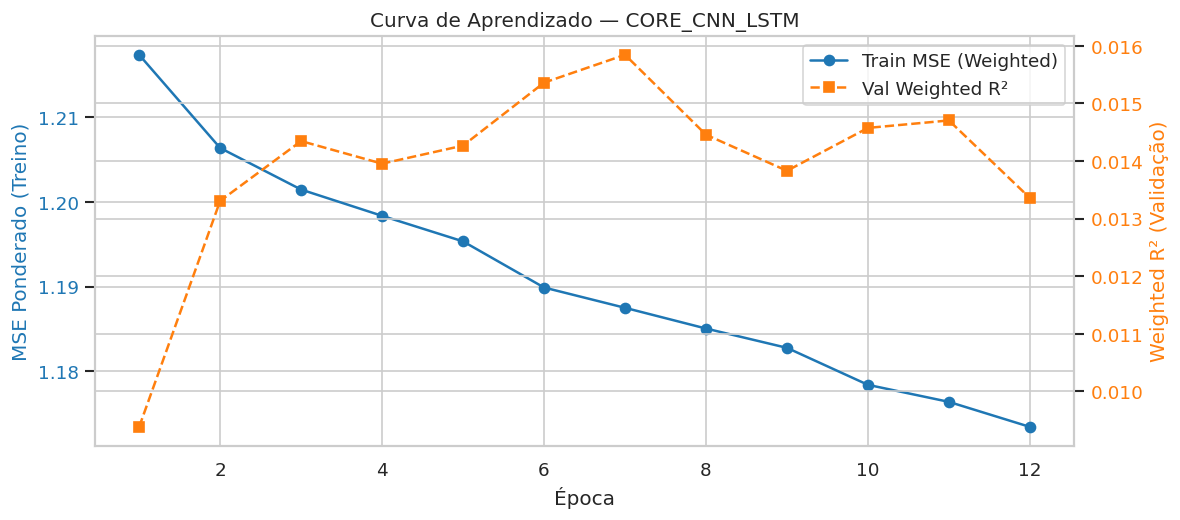

In [11]:
# 6.2 Curvas de aprendizado (Loss ponderada de treino vs. Weighted R² de validação)
epocas_idx = np.arange(1, len(hist.history["loss"]) + 1)

fig, ax1 = plt.subplots(figsize=(10, 4.5))
l1 = ax1.plot(epocas_idx, hist.history["loss"], color="#1f77b4", marker="o", label="Train MSE (Weighted)")
ax1.set_xlabel("Época")
ax1.set_ylabel("MSE Ponderado (Treino)", color="#1f77b4")
ax1.tick_params(axis="y", labelcolor="#1f77b4")

ax2 = ax1.twinx()
l2 = ax2.plot(epocas_idx, r2_cb.history_r2, color="#ff7f0e", marker="s", linestyle="--", label="Val Weighted R²")
ax2.set_ylabel("Weighted R² (Validação)", color="#ff7f0e")
ax2.tick_params(axis="y", labelcolor="#ff7f0e")

linhas = l1 + l2
rotulos = [l.get_label() for l in linhas]
ax1.legend(linhas, rotulos, loc="best", frameon=True)

plt.title(f"Curva de Aprendizado — {PREFIXO.upper()}")
plt.tight_layout()
plt.savefig(os.path.join(GRAPHS_DIR, f"{PREFIXO}_learning_curves.png"), dpi=200, bbox_inches="tight")
plt.show()

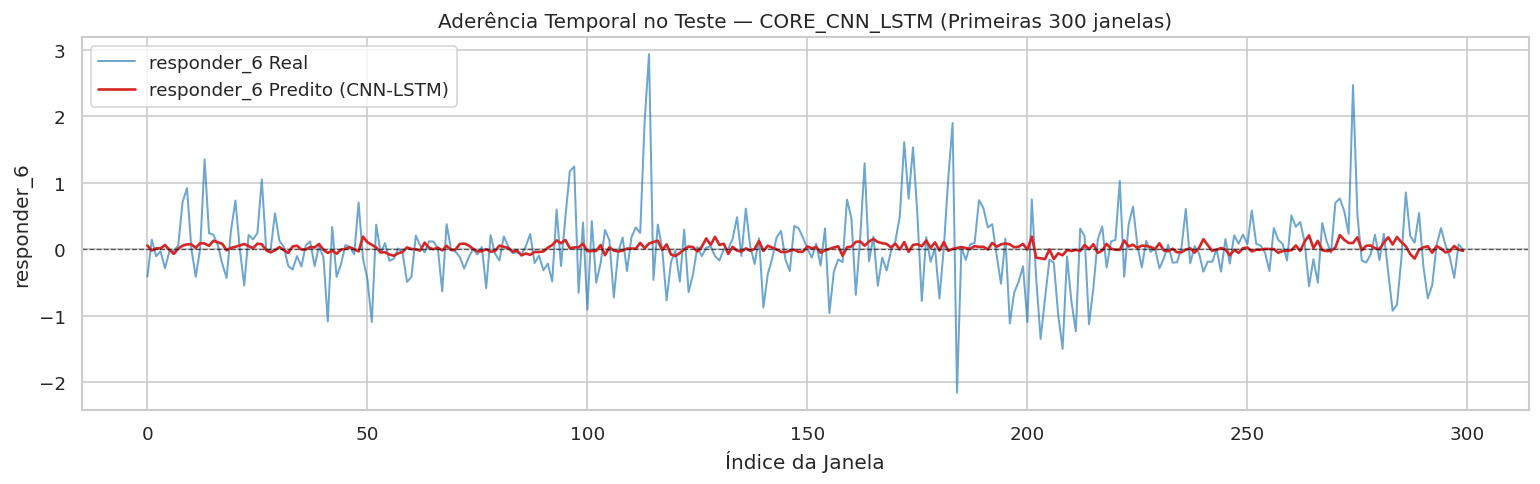

5442

In [12]:
# 6.3 Aderência temporal: real vs. predito em uma amostra consecutiva do conjunto de teste
n_vis = min(300, len(y_t))
plt.figure(figsize=(13, 4.2))
plt.plot(y_t[:n_vis], color="#1f77b4", alpha=0.65, lw=1.2, label="responder_6 Real")
plt.plot(y_p[:n_vis], color="#d62728", lw=1.6, label="responder_6 Predito (CNN-LSTM)")
plt.axhline(0, color="black", linestyle="--", lw=0.8, alpha=0.6)
plt.title(f"Aderência Temporal no Teste — {PREFIXO.upper()} (Primeiras {n_vis} janelas)")
plt.xlabel("Índice da Janela")
plt.ylabel("responder_6")
plt.legend(frameon=True)
plt.tight_layout()
plt.savefig(os.path.join(GRAPHS_DIR, f"{PREFIXO}_pred_vs_real.png"), dpi=200, bbox_inches="tight")
plt.show()

del test_df, test_ds, best_model
gc.collect()

---
## 7. Consolidação dos Resultados e Comparação Direta com o Core LSTM

### 7.1 Comparativo Quantitativo (`core_cnn_lstm` vs. `core_lstm`)

| Modelo | Split | Weighted $R^2$ | $\Delta R^2$ vs. LSTM | RMSE (Pond.) | MAE (Pond.) | Melhor Época | Parâmetros | Tempo (min) |
| :--- | :--- | :---: | :---: | :---: | :---: | :---: | :---: | :---: |
| **`core_lstm` (Baseline)** | Validação (15%) | `+0.015193` | `0.000000` | `0.70711` | `0.46267` | `5` *(stop em 10)* | `31.105` | `13,26` |
| **`core_cnn_lstm`** | Validação (15%) | **`+0.015846`** | **`+0.000653` (+4,30%)** | **`0.70687`** | **`0.46202`** | `7` *(stop em 12)* | `44.993` | `15,86` |
| **`core_lstm` (Baseline)** | Teste (15%) | **`+0.002602`** | `0.000000` | `0.73355` | `0.48372` | — | `31.105` | `13,26` |
| **`core_cnn_lstm`** | Teste (15%) | `+0.002594` | `-0.000008` (-0,31%) | `0.73355` | **`0.48337`** | — | `44.993` | `15,86` |

### 7.2 Análise Crítica (Pronta para Artigo e Slides)

1. **Ganho consistente na Validação (`+4,30%` relativo em $R^2$):** A camada `Conv1D` causal seguida de `MaxPooling1D` elevou o *Weighted $R^2$* de validação de `+0.015193` para **`+0.015846`** (`+0.000653`), melhorando simultaneamente `RMSE` (`0.70711` → `0.70687`) e `MAE` (`0.46267` → `0.46202`).
2. **Empate técnico no Teste sob *Regime Shift*:** No conjunto futuro intocado (`date_id` 1548–1698), `core_cnn_lstm` (`+0.002594`, `RMSE = 0.73355`, `MAE = 0.48337`) empatou tecnicamente com `core_lstm` (`+0.002602`, `RMSE = 0.73355`, `MAE = 0.48372`), reforçando que o gargalo no horizonte distante é o *concept drift* (e não apenas a capacidade de extração local).
3. **Custo-benefício arquitetural:** Com `+44,6%` de parâmetros (`44.993` vs. `31.105`, ainda leve: `175,75 KB`) e ~2,6 min extras de treino (convergindo na época 7 vs. época 5), a **CNN–LSTM superou a LSTM pura em validação** mantendo a mesma robustez em teste.

---
## 8. Artefatos Exportados e Próximos Passos

- **Checkpoint salvo:** `models/core_cnn_lstm.keras`
- **Histórico de épocas:** `models/core_cnn_lstm_history.csv`
- **Figuras para o artigo/slides:** `graphs/core_cnn_lstm_learning_curves.png` e `graphs/core_cnn_lstm_pred_vs_real.png`
- **Próximos experimentos:** Comparar **GRU** e **LSTM + Self-Attention** sob o mesmo protocolo controlado, seguidos das ablações (Blocos A–E).